*  DSC540-T303 Data Preparation (2265-1)
*  Weeks 9 & 10 Exercises
*  David Jorgensen

# Weeks 9 & 10 Exercises

## Part 1: Activity 7.01

Project Gutenberg encourages the creation and distribution of eBooks by encouraging volunteer efforts to digitize and archive cultural works. This activity aims to scrape the URL of [Project Gutenberg's Top 100 eBooks](https://www.gutenberg.org/browse/scores/top) to identify the eBooks' links. It uses BeautifulSoup to parse the HTML and regular expression code to identify the Top 100 eBook file numbers. You can use these numbers to download the book into your local drive if you want. 

These are the steps that will help you complete this activity: 
- Import the necessary libraries, including regex and BeautifulSoup. 
- Read the HTML from the URL "https://www.gutenberg.org/browse/scores/top".
- Write a small function to check the status of the web request. 
- Decode the response and pass this on to BeautifulSoup for HTML parsing. 
- Find all the href tags and store them in the list of links. Check what the list looks like – print the first 30 elements. 
- Use a regular expression to find the numeric digits in these links. These are the file numbers for the top 100 eBooks. 
- Initialize the empty list to hold the file numbers over an appropriate range and use regex to find the numeric digits in the link href string. Hint: Use the `findall` method. 
- What does the soup object's text look like? Use the `.text` method and print only the first 2,000 characters (do not print the whole thing, as it is too long). 
- Search in the extracted text (using a regular expression) from the soup object to find the names of the top 100 eBooks (yesterday's ranking). 
- Create a starting index. It should point at the text Top 100 Ebooks yesterday. Use the `splitlines` method of `soup.text`. It splits the lines of text of the soup object. 
- Run the for loop 1-100 to add the strings of the next 100 lines to this temporary list. Hint: use the `splitlines` method. 
- Use a regular expression to extract only text from the name strings and append it to an empty list. Use `match` and `span` to find the indices and use them. 
- Print the list of titles. 

In [32]:
# Import libraries
import re
import bs4
import urllib.request

In [33]:
# Read HTML from URL
url = "https://www.gutenberg.org/browse/scores/top"

HEADERS = {
    'User-Agent': 'Mozilla/5.0 (X11; Linux x86_64; rv:125.0) Gecko/20100101 Firefox/125.0',
    'Accept': 'text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8',
    'Accept-Language': 'en-US,en;q=0.5',
}

# Function to check status of web request
def check_status(url):
    req = urllib.request.Request(url, headers=HEADERS)
    response = urllib.request.urlopen(req)
    if response.status == 200:
        print(f"Web request status: {response.status} - OK")
    else:
        print(f"Web request status: {response.status} - Error")
    return response

response = check_status(url)

Web request status: 200 - OK


In [34]:
# Decode response and pass to BeautifulSoup for HTML parsing
html = response.read().decode('utf-8')
soup = bs4.BeautifulSoup(html, 'html.parser')

# Narrow to li elements inside div.page_content > ol
# The first ol = "Top 100 EBooks yesterday", second = "Top 100 Authors yesterday", etc.
ols = soup.select('div.page_content > ol')
print(f"Ordered lists found in page_content: {len(ols)}")

Ordered lists found in page_content: 6


In [35]:
yesterday_ol = ols[0]  # first ol = Top 100 EBooks yesterday
li_items = yesterday_ol.find_all('li')
print(f"li items in first ol: {len(li_items)}")

li items in first ol: 100


In [36]:
# Collect href links from li elements; print first 30
links = []
for li in li_items:
    a = li.find('a', href=True)
    if a:
        links.append(a['href'])

print(f"\nFirst 30 links:")
for link in links[:30]:
    print(link)


First 30 links:
/ebooks/2701
/ebooks/1342
/ebooks/84
/ebooks/27509
/ebooks/1184
/ebooks/2554
/ebooks/1513
/ebooks/2641
/ebooks/11
/ebooks/43
/ebooks/145
/ebooks/67979
/ebooks/1260
/ebooks/64317
/ebooks/45304
/ebooks/100
/ebooks/245
/ebooks/26225
/ebooks/7142
/ebooks/345
/ebooks/5197
/ebooks/27558
/ebooks/65662
/ebooks/1661
/ebooks/8492
/ebooks/28054
/ebooks/37106
/ebooks/1259
/ebooks/22120
/ebooks/19771


In [37]:
# Use regex findall to extract file numbers from links
file_numbers = []
for link in links:
    result = re.findall(r'/ebooks/(\d+)', link)
    if result:
        file_numbers.append(result[0])

print(f"\nTop 100 eBook file numbers ({len(file_numbers)} found):")
print(file_numbers)


Top 100 eBook file numbers (100 found):
['2701', '1342', '84', '27509', '1184', '2554', '1513', '2641', '11', '43', '145', '67979', '1260', '64317', '45304', '100', '245', '26225', '7142', '345', '5197', '27558', '65662', '1661', '8492', '28054', '37106', '1259', '22120', '19771', '3296', '22091', '50528', '34413', '2680', '25851', '21002', '28046', '23784', '3268', '768', '120', '65238', '21092', '2868', '27713', '2465', '24919', '69944', '3011', '20990', '50285', '74', '25977', '26849', '174', '76', '23403', '844', '16389', '98', '40739', '23445', '24950', '25112', '22788', '72', '25868', '22749', '7326', '161', '75201', '5740', '2160', '6761', '26408', '394', '20872', '27553', '1695', '6133', '24855', '4085', '20946', '22815', '26514', '23458', '19476', '65661', '6593', '25049', '25919', '55', '22304', '42671', '1727', '22163', '62215', '59828', '21436']


In [38]:
# Print first 2,000 characters of soup.text
print("\nFirst 2,000 characters of book list (soup.text):")
print(soup.text[:2000])


First 2,000 characters of book list (soup.text):




Top 100 | Project Gutenberg


































X

Go!







 Donate 




About▼

About Project Gutenberg 
Reading Options & Kindle
Contact Us
History & Philosophy
Help Pages
Offline Catalogs
Donate



Frequently Downloaded
Main Categories
Reading Lists
Search Options



Frequently Downloaded
Main Categories



Frequently Viewed or Downloaded

Click here to see download statistics
Calculated from the number of times each eBook gets
downloaded. (Multiple downloads from the same Internet
address on the same day count as one download. Addresses
that download more than 100 eBooks in a day are considered
robots and are not counted.)

Downloaded Books
2026-05-182713358
last 7 days20710990
last 30 days74892441

Visualizations and graphs are available as
pretty pictures.
 

Top 100 EBooks: Yesterday - 7 days - 30 days
Top 100 Authors: Yesterday - 7 days - 30 days

Top 100 EBooks yesterday

Moby Dick; Or, The Whale by Herman M

In [39]:
# Search soup.text for "Top 100 EBooks yesterday" using splitlines
lines = soup.text.splitlines()

# Create starting index pointing at "Top 100 EBooks yesterday"
start_idx = None
for i, line in enumerate(lines):
    if re.search(r'Top 100 EBooks yesterday', line):
        start_idx = i
        print(f"\nFound 'Top 100 EBooks yesterday' at line index {i}")
        break

# Run for loop 1-100 to add next 100 lines to temp list
temp_list = []
for i in range(2, 102): # Starts at 2 to omit header and empty line
    temp_list.append(lines[start_idx + i])

print(f"\nSample temp_list entries:")
for entry in temp_list[:5]:
    print(f"  '{entry}'")


Found 'Top 100 EBooks yesterday' at line index 99

Sample temp_list entries:
  'Moby Dick; Or, The Whale by Herman Melville (5134)'
  'Pride and Prejudice by Jane Austen (4414)'
  'Frankenstein; or, the modern prometheus by Mary Wollstonecraft Shelley (4412)'
  'The 2006 CIA World Factbook by United States. Central Intelligence Agency (3553)'
  'The Count of Monte Cristo by Alexandre Dumas and Auguste Maquet (3506)'


In [40]:
# Use regex (match + span) to extract only text from name strings.
# soup.text does not include ol numbering, so match any non-whitespace
# character to skip blank lines and capture the full title string.
titles = []
for name in temp_list:
    name = name.strip()
    match = re.match(r'\S.*', name)
    if match:
        s, e = match.span()
        titles.append(name[s:e])

# Print list of titles
print(f"\nTop 100 eBook Titles ({len(titles)} found):")
for i, title in enumerate(titles, 1):
    print(f"{i}. {title}")


Top 100 eBook Titles (100 found):
1. Moby Dick; Or, The Whale by Herman Melville (5134)
2. Pride and Prejudice by Jane Austen (4414)
3. Frankenstein; or, the modern prometheus by Mary Wollstonecraft Shelley (4412)
4. The 2006 CIA World Factbook by United States. Central Intelligence Agency (3553)
5. The Count of Monte Cristo by Alexandre Dumas and Auguste Maquet (3506)
6. Crime and Punishment by Fyodor Dostoyevsky (3190)
7. Romeo and Juliet by William Shakespeare (3151)
8. A Room with a View by E. M.  Forster (3070)
9. Alice's Adventures in Wonderland by Lewis Carroll (2746)
10. The strange case of Dr. Jekyll and Mr. Hyde by Robert Louis Stevenson (2733)
11. Middlemarch by George Eliot (2601)
12. The Blue Castle: a novel by L. M.  Montgomery (2300)
13. Jane Eyre: An Autobiography by Charlotte Brontë (2274)
14. The Great Gatsby by F. Scott  Fitzgerald (2215)
15. The City of God, Volume I by Saint of Hippo Augustine (2206)
16. The Complete Works of William Shakespeare by William Shakesp

## Part 2: Activity 7.02

In this activity, you will build a complete movie database by communicating and interfacing with a free API from the OMDb portal http://www.omdbapi.com/?. You will obtain a unique user key from the OMDb website that must be used when your program tries to access the API. Then, you will need to store this key value in a .json file. 

The aims of this activity are as follows: 
- To retrieve and print basic data about a movie (the title is entered by the user) from the web (the OMDb database).
- If a poster of the movie can be found, download the file and save it in a user-specified location. 

These are the steps that will help you complete this activity:
1. Import `urllib.request`, `urllib.parse`, `urllib.error`, and `json`. 
2. Load the secret API key (you have to get one from the OMDb website and use that; it has a daily limit of 1,000 API keys) from a JSON file, stored in the same folder, in a variable. Hint: Use `json.loads()`. Students/users will need to obtain a key and store it in a JSON file. 
3. Obtain a key and store it in a JSON file as `APIkeys.json`. 
4. Open the `APIkeys.json` file. 
5. Assign the OMDb portal (http://www.omdbapi.com/?) as a string to a variable. 
6. Create a variable called apikey with the last portion of the URL (`&apikey=secretapikey`), where secretapikey is your own API key. 
7. Write a utility function called `print_json` to print the movie data from a JSON file (which we will get from the portal). 
8. Write a utility function to download a poster of the movie based on the information from the JSON dataset and save it in your local folder. Use the os module. The poster data is stored in a JSON key called Poster. Use the open Python command to open a file and write the poster data. Close the file after you're done. This function will save the poster data as an image file. 
9.  Write a utility function called `search_movie` to search for a movie by its name, print the downloaded JSON data, and save the movie poster in the local folder. Use a try-except loop for this. Use the previously created serviceurl and apikey variables. You have to pass on a dictionary with a key, `t`, and the movie name as the corresponding value to the `urllib.parse.urlencode()` function and then add the serviceurl and apikey variables to the output of the function to construct the full URL. This URL will be used to access the data. The JSON data has a key called Response. If it is `True`, that means the read was successful. Check this before processing the data. If it's not successful, then print the JSON key Error, which will contain the appropriate error message returned by the movie database. 
10.  Test the `search_movie` function by entering Titanic.
11.  Test the `search_movie` function by entering `Random_error` and retrieve the data for `Random_error` (obviously, this will not be found, and you should be able to check whether your error-catching code is working properly).
Look for a folder called Posters in the same directory you are working in. It should contain a file called `Titanic.jpg`. Check the file. 

In [44]:
import urllib.request
import urllib.parse
import urllib.error
import json
import os

# Load API key from APIkeys.json
with open('APIkeys.json') as f:
    keys = json.loads(f.read())
omdb_key = keys['OMDb']

# OMDb service URL and apikey suffix
serviceurl = 'http://www.omdbapi.com/?'
apikey = f'&apikey={omdb_key}'

HEADERS = {
    'User-Agent': 'Mozilla/5.0 (X11; Linux x86_64; rv:125.0) Gecko/20100101 Firefox/125.0',
    'Accept': 'application/json',
    'Accept-Language': 'en-US,en;q=0.5',
}

# Utility: pretty-print JSON movie data
def print_json(data):
    for k, v in data.items():
        print(f'{k:15}: {v}')

# Utility: download and save movie poster
def save_poster(data, folder='Posters'):
    poster_url = data.get('Poster')
    if not poster_url or poster_url == 'N/A':
        print('No poster available.')
        return
    os.makedirs(folder, exist_ok=True)
    title = data.get('Title', 'unknown').replace(' ', '_')
    filepath = os.path.join(folder, f'{title}.jpg')
    req = urllib.request.Request(poster_url, headers=HEADERS)
    poster_data = urllib.request.urlopen(req).read()
    with open(filepath, 'wb') as f:
        f.write(poster_data)
    print(f'Poster saved: {filepath}')

# Utility: search movie by name, print data, save poster
def search_movie(title):
    try:
        params = urllib.parse.urlencode({'t': title})
        url = serviceurl + params + apikey
        req = urllib.request.Request(url, headers=HEADERS)
        with urllib.request.urlopen(req) as response:
            data = json.loads(response.read().decode('utf-8'))
        if data.get('Response') == 'True':
            print_json(data)
            save_poster(data)
        else:
            print(f'Error: {data.get("Error")}')
    except urllib.error.URLError as e:
        print(f'URLError: {e.reason}')

# Test 1: valid movie
print('=== Titanic ===')
search_movie('Titanic')

# Test 2: invalid movie (error-handling check)
print('\n=== Random_error ===')
search_movie('Random_error')

=== Titanic ===
Title          : Titanic
Year           : 1997
Rated          : PG-13
Released       : 19 Dec 1997
Runtime        : 194 min
Genre          : Drama, Romance
Director       : James Cameron
Writer         : James Cameron
Actors         : Leonardo DiCaprio, Kate Winslet, Billy Zane
Plot           : A seventeen-year-old aristocrat falls in love with a kind but poor artist aboard the luxurious, ill-fated R.M.S. Titanic.
Language       : English, Swedish, Italian, French
Country        : United States, Mexico
Awards         : Won 11 Oscars. 126 wins & 84 nominations total
Poster         : https://m.media-amazon.com/images/M/MV5BYzYyN2FiZmUtYWYzMy00MzViLWJkZTMtOGY1ZjgzNWMwN2YxXkEyXkFqcGc@._V1_QL75_UX380_CR0,2,380,562_.jpg
Ratings        : [{'Source': 'Internet Movie Database', 'Value': '8.0/10'}, {'Source': 'Rotten Tomatoes', 'Value': '88%'}, {'Source': 'Metacritic', 'Value': '75/100'}]
Metascore      : 75
imdbRating     : 8.0
imdbVotes      : 1,389,357
imdbID         : tt01203

## Part 3: API Data Pull

Connect to an API of your choice ([Space Devs Launch Library](https://ll.thespacedevs.com/2.3.0/launches/)) and do a simple data pull.
- In previous versions of this course we have always used Twitter, but with recent organizational changes at Twitter, it has become increasingly difficult to access the free APIs available at Twitter. You are more than welcome to try to use Twitter's API for this portion of the assignment, but please note, there has been some inconsistency experienced when following along with their documentation posted.
- Connect to the API and do a "Get" call/operation on the API to return a subset of data from the API

In [48]:
import urllib.request
import urllib.parse
import json
from datetime import datetime, timezone
from IPython.display import HTML, display

HEADERS = {
    'User-Agent': 'Mozilla/5.0 (X11; Linux x86_64; rv:125.0) Gecko/20100101 Firefox/125.0',
    'Accept': 'application/json',
}

# Fetch next 5 upcoming launches; use first with a future NET time
url = 'https://ll.thespacedevs.com/2.3.0/launches/upcoming/?limit=5&format=json'
req = urllib.request.Request(url, headers=HEADERS)
with urllib.request.urlopen(req) as response:
    data = json.loads(response.read().decode('utf-8'))

now_utc = datetime.now(timezone.utc)

def is_future(r):
    net_str = r.get('net', '')
    if not net_str:
        return False
    net_dt = datetime.fromisoformat(net_str.replace('Z', '+00:00'))
    return net_dt > now_utc

launch = next((r for r in data['results'] if is_future(r)), data['results'][-1])

In [58]:
# Extract fields
name        = launch.get('name', 'Unknown')
net         = launch.get('net', '')
status_name = launch.get('status', {}).get('name', 'Unknown')
image_url   = launch.get('image', {}).get('image_url') if launch.get('image') else None
rocket_name = launch.get('rocket', {}).get('configuration', {}).get('name', 'Unknown')

provider    = launch.get('launch_service_provider', {})
agency_name = provider.get('name', 'Unknown')
agency_url  = provider.get('url', '#')

info_urls   = launch.get('infoURLs', [])
info_url    = info_urls[0].get('url', '#') if info_urls else '#'

In [ ]:
# Build HTML card with JS countdown
html = f"""
<style>
  .launch-card {{
    font-family: 'Segoe UI', Arial, sans-serif;
    max-width: 520px;
    border-radius: 12px;
    overflow: hidden;
    box-shadow: 0 4px 18px rgba(0,0,0,0.18);
    background: #0d1b2a;
    color: #e8f0fe;
  }}
  .launch-card img {{
    width: 100%;
    height: 220px;
    object-fit: cover;
    display: block;
  }}
  .launch-card .no-img {{
    width: 100%;
    height: 220px;
    background: #1a2f4a;
    display: flex;
    align-items: center;
    justify-content: center;
    font-size: 2rem;
    color: #4a7ab5;
  }}
  .launch-body {{ padding: 20px 24px 24px; }}
  .launch-status {{
    display: inline-block;
    padding: 3px 10px;
    border-radius: 20px;
    font-size: 0.75rem;
    font-weight: 600;
    background: #1c4f8a;
    color: #7ec8e3;
    margin-bottom: 10px;
    letter-spacing: 0.04em;
    text-transform: uppercase;
  }}
  .launch-name {{
    font-size: 1.2rem;
    font-weight: 700;
    margin: 0 0 6px;
    line-height: 1.3;
  }}
  .launch-rocket {{
    font-size: 0.9rem;
    color: #a0bcd8;
    margin-bottom: 16px;
  }}
  .launch-links {{ margin-bottom: 18px; }}
  .launch-links a {{
    display: inline-block;
    margin-right: 10px;
    padding: 5px 14px;
    border-radius: 6px;
    font-size: 0.82rem;
    font-weight: 600;
    text-decoration: none;
    background: #1c4f8a;
    color: #7ec8e3;
    transition: background 0.2s;
  }}
  .launch-links a:hover {{ background: #2563a8; }}
  .countdown-label {{
    font-size: 0.75rem;
    text-transform: uppercase;
    letter-spacing: 0.08em;
    color: #7ec8e3;
    margin-bottom: 8px;
  }}
  .launched-msg {{
    font-size: 1rem;
    color: #4ade80;
    font-weight: 600;
  }}
</style>

<div class="launch-card">
  {'<img src="' + image_url + '" alt="Launch thumbnail">' if image_url else '<div class="no-img">&#128640;</div>'}
  <div class="launch-body">
    <div class="launch-status">{status_name}</div>
    <div class="launch-name">{name}</div>
    <div class="launch-rocket">Rocket: {rocket_name} &nbsp;&bull;&nbsp; {agency_name}</div>
    <div class="launch-links">
      <a href="{agency_url}" target="_blank">Agency</a>
      <a href="{info_url}" target="_blank">Mission Info</a>
    </div>
    <div class="countdown-label">Scheduled Launch Time</div>
    <div class="launched-msg launch-datetime"></div>
  </div>
</div>

<script>
(function() {{
  var target = new Date("{net}");
  document.getElementsByClassName('launch-datetime')[0].innerHTML = target;
}})();
</script>
"""

display(HTML(html))

## Part 4: Visualizatons

Using `./weeks_9-10_data/vote_ai.csv`, choose 3 of the following visualizations to complete. You are free to use Matplotlib, Seaborn or another package if you prefer.
- Line
- Scatter
- Bar
- Histogram
- Density Plot
- Pie Chart

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

df = pd.read_csv('./weeks_9-10_data/vote_ai.csv')
print(df.shape)
df.head(3)

(22000, 62)


,Election_ID,State,Constituency_Code,Constituency_Name,Round,Last_Updated_Time,Candidate_Name,Party,Gender,Age,...,Network_Failure_Count,Power_Outage_Risk,Noise_Float_1,Noise_Float_2,Noise_Category,Correlated_Noise_Score,Fraud_Proxy_Duplicate,Election_Result,Fraud_Label,Risk_Category
0,137591d6-2b7b-47af-8ed2-f68e1f5434f6,Bihar,C0008,Nagpur,5,2024-05-21T15:28:18.800054+05:53,Yochana Khurana,YSRCP,Male,57,...,6,0.2407,21.980,31.310,D,0.1434,0.4657,Won,1,High
1,96fb1c8e-c776-4f82-b883-509719f7dadf,Assam,C0317,Sambalpur,1,2024-04-20T02:42:43.430954+05:53,Zansi Tara,NCP,Male,53,...,5,0.0965,94.401,76.622,B,0.3228,0.4280,Won,1,Medium
2,973a3ec0-a2cd-4161-bce9-f9592435f64c,Madhya Pradesh,C0027,Kolhapur,3,2024-05-07T18:43:18.086654+05:53,Falguni Gaba,Independent,Male,63,...,2,0.2881,78.950,70.513,B,0.6605,0.1211,Won,0,Low


### Visualization 1: Bar Chart Average Popularity Score by Party (Top 10)

Which parties field the most popular candidates on average? A bar chart of mean `Popularity_Score` for the 10 largest parties makes it easy to compare.

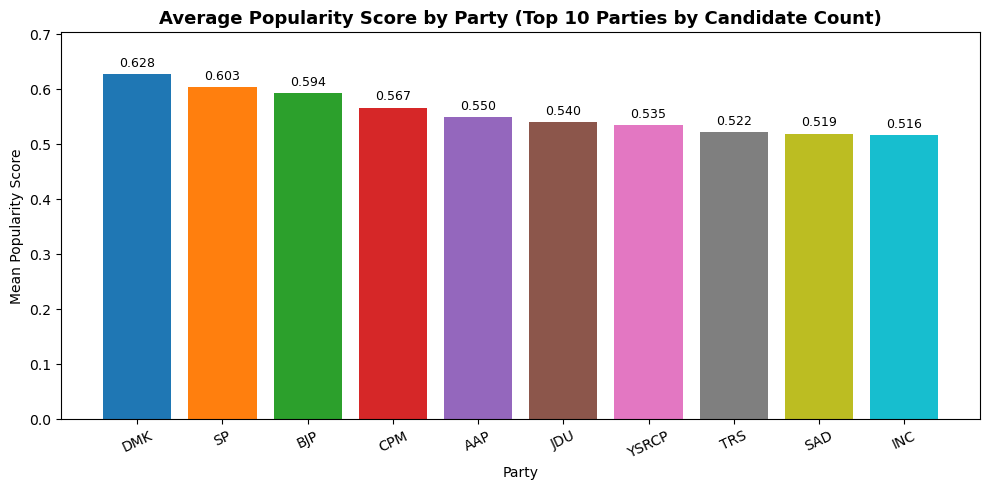

In [62]:
top_parties = df['Party'].value_counts().head(10).index
party_pop = (
    df[df['Party'].isin(top_parties)]
    .groupby('Party')['Popularity_Score']
    .mean()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(party_pop.index, party_pop.values, color=sns.color_palette('tab10', len(party_pop)))
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_title('Average Popularity Score by Party (Top 10 Parties by Candidate Count)', fontsize=13, fontweight='bold')
ax.set_xlabel('Party')
ax.set_ylabel('Mean Popularity Score')
ax.set_ylim(0, party_pop.max() * 1.12)
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

### Visualization 2: Histogram Distribution of Vote Percentage

How are votes distributed across all candidates? A histogram of `Vote_Percentage` reveals whether most races are competitive or lopsided.

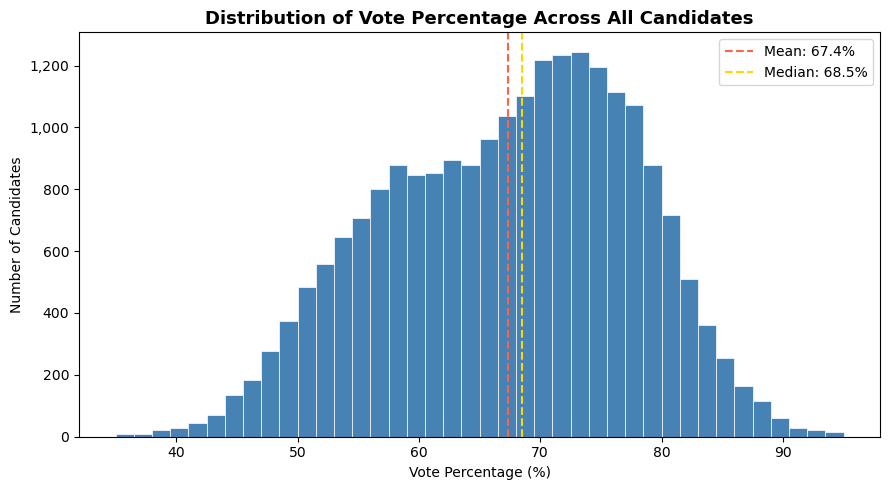

In [63]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df['Vote_Percentage'].dropna(), bins=40, color='steelblue', edgecolor='white', linewidth=0.5)
ax.axvline(df['Vote_Percentage'].mean(), color='tomato', linestyle='--', linewidth=1.5, label=f"Mean: {df['Vote_Percentage'].mean():.1f}%")
ax.axvline(df['Vote_Percentage'].median(), color='gold', linestyle='--', linewidth=1.5, label=f"Median: {df['Vote_Percentage'].median():.1f}%")
ax.set_title('Distribution of Vote Percentage Across All Candidates', fontsize=13, fontweight='bold')
ax.set_xlabel('Vote Percentage (%)')
ax.set_ylabel('Number of Candidates')
ax.legend()
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()

### Visualization 3: Scatter Plot Campaign Spending vs. Popularity Score

Does spending more correlate with higher popularity? A scatter plot of `Campaign_Spending_Cr` vs `Popularity_Score`, colored by election outcome, lets us see if money translates to votes.

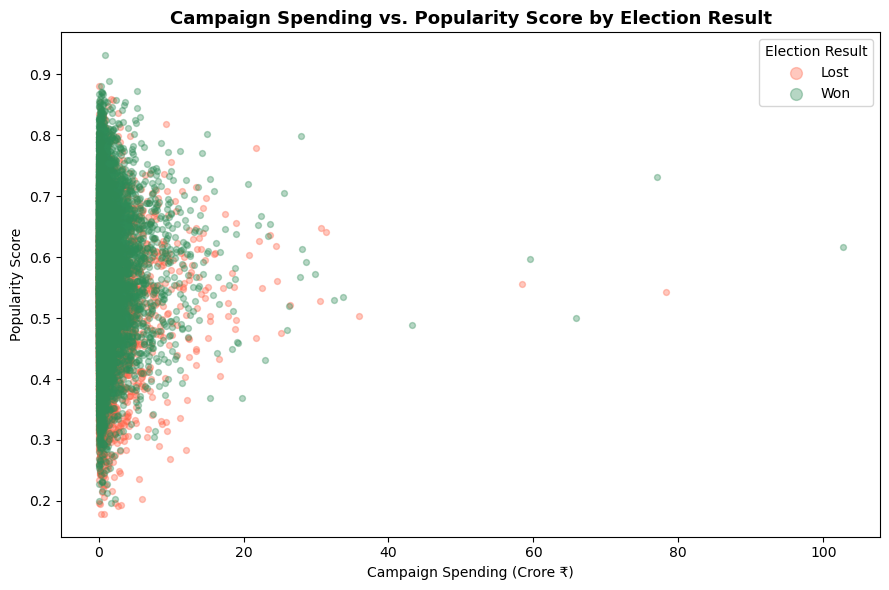

Pearson correlation (spending vs popularity): 0.0058


In [64]:
plot_df = df[['Campaign_Spending_Cr', 'Popularity_Score', 'Election_Result']].dropna()
colors = {'Won': 'seagreen', 'Lost': 'tomato'}

fig, ax = plt.subplots(figsize=(9, 6))
for result, group in plot_df.groupby('Election_Result'):
    ax.scatter(
        group['Campaign_Spending_Cr'],
        group['Popularity_Score'],
        c=colors.get(result, 'gray'),
        alpha=0.35,
        s=18,
        label=result,
        rasterized=True,
    )

ax.set_title('Campaign Spending vs. Popularity Score by Election Result', fontsize=13, fontweight='bold')
ax.set_xlabel('Campaign Spending (Crore ₹)')
ax.set_ylabel('Popularity Score')
ax.legend(title='Election Result', markerscale=2)
plt.tight_layout()
plt.show()

# Correlation
corr = plot_df['Campaign_Spending_Cr'].corr(plot_df['Popularity_Score'])
print(f"Pearson correlation (spending vs popularity): {corr:.4f}")